# CellTransformer2 on your own dataset

This notebook runs the native CellTransformer2 commands step by step:
`celltransformer-preprocess` → `celltransformer-train` → `celltransformer-extract` → `celltransformer-smooth` → `celltransformer-cluster`.
Training is configured with Hydra: every setting in `config/` can be overridden from the command
line, and this notebook builds those overrides from the values you choose.

As a worked example it uses five sections of the Allen 1 MERFISH data (the same files as `01_allen_dataset.ipynb`),
downloaded in Step 1. Cells and variables marked **REPLACE WITH YOUR DATA** are where you
point it at your own files.

**Requirements:** Linux x86_64 and an NVIDIA GPU with bfloat16 support. Two environments,
both with the package installed (`pip install -e .` from the repository):
- a training environment (this notebook's kernel), and
- a RAPIDS environment with cuML, used for smoothing and clustering.

`helper.py` next to this notebook holds the plumbing (running commands, environment checks, background
training, plot display); nothing in it needs editing for your data.

**Input contract.** Every later step reads the standard input written in Step 3, one pair per section:
an `.h5ad` of raw counts (cells × genes) in `layers['raw']` and a paired `.parquet` of the same cells, in the same order,
with columns `section`, `x`, `y` (µm) and `cell_type`. Row *i* of the metadata must describe row *i* of
the count matrix.

## Step 1: set paths and dataset columns
● TIMING <1 min, plus the first download (~9.3 GB)

Set `WORK_DIR` and `RAPIDS_BIN` below. The next cell downloads the example Allen files (~9.3 GB) into
`ALLEN_ROOT/data/raw/`; skip it if you use your own data.

**REPLACE WITH YOUR DATA:** everything in the first block below. `SECTIONS` selects which tissue
sections to use; `VALID_SECTIONS` are held out entirely from training and used only for the
validation loss (split by section, not by cell, so validation measures generalization to unseen tissue).

In [15]:
import sys
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import yaml

import helper

#REPLACE WITH YOUR DATA: raw count matrix (.h5ad) and per-cell metadata (.csv or .parquet)
#(for the example, the next cell downloads the Allen files into ALLEN_ROOT/data/raw/)
# ALLEN_ROOT = Path("~/allen_data").expanduser().resolve()
ALLEN_ROOT = Path("/home/rotation/sara_rotation/celltrans2-test/notebooks/notebook1_modular")                                #sara local
RAW_H5AD = ALLEN_ROOT / "data/raw/expression_raw.h5ad"
RAW_METADATA = ALLEN_ROOT / "data/raw/cells_ccf.csv"

#REPLACE WITH YOUR DATA: metadata column names
CELL_ID_COL = "cell_label"            #matches the .h5ad obs_names
SECTION_COL = "brain_section_label"
CELL_TYPE_COL = "subclass"
X_COL = "x_reconstructed"
Y_COL = "y_reconstructed"
COORD_TO_UM = 1000.0                  #multiply coordinates by this to get µm (Allen stores mm)

#REPLACE WITH YOUR DATA: genes to drop (here, MERFISH blank control probes), matched on this var column
GENE_SYMBOL_COL = "gene_symbol"
DROP_GENE_PREFIX = "Blank"

#REPLACE WITH YOUR DATA: sections to use and sections held out for validation
SECTIONS = [f"C57BL6J-638850.{n}" for n in [28, 29, 30, 31, 32]]
VALID_SECTIONS = ["C57BL6J-638850.30"]

#working directory for everything this notebook writes
# WORK_DIR = Path("~/ct2_runs/custom").expanduser().resolve()
WORK_DIR = Path("/home/rotation/sara_rotation/celltrans2-test/notebooks/notebook2")                                  #sara local

#bin/ directories of the two environments: this kernel's, and the RAPIDS one (set this)
DEV_BIN = Path(sys.executable).parent
#REPLACE WITH YOUR ENV: bin/ of celltransformer2-rapids; run `conda env list` and add /bin to its path
# RAPIDS_BIN = Path("/path/to/rapids-env/bin").resolve()
RAPIDS_BIN = Path("~/miniconda3/envs/celltransformer2/bin").expanduser().resolve()                     #sara local

#derived paths
INPUT_DIR = WORK_DIR / "input"
SECTIONS_DIR = WORK_DIR / "sections"
SMOOTHED_DIR = WORK_DIR / "sections_smoothed"
CHECKPOINT_DIR = WORK_DIR / "checkpoints"
DOMAINS_DIR = WORK_DIR / "domains"
TAXONOMY = WORK_DIR / "taxonomy.yaml"
TRAIN_LOG = WORK_DIR / "train.log"
for d in [INPUT_DIR, SECTIONS_DIR, CHECKPOINT_DIR, DOMAINS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

In [16]:
%%time
#example data only: download the raw Allen files (~9.3 GB) and verify their checksums; verified files are skipped
helper.download_allen(ALLEN_ROOT)

Download/checksum: expression_raw.h5ad (7.628 GB)
Download/checksum: cells_ccf.csv (1.607 GB)
Download/checksum: gene.csv (0.000 GB)
Download/checksum: taxonomy.csv (0.001 GB)
Download/checksum: parcellation_terms.csv (0.000 GB)
Download/checksum: parcellation_membership.csv (0.001 GB)
Download/checksum: parcellation_acronyms.csv (0.000 GB)
Download/checksum: registered_annotation.nii.gz (0.002 GB)
Download/checksum: ccf_annotation_10.nii.gz (0.028 GB)
ALLEN 1 PUBLIC DATA DOWNLOAD: PASSED


## Step 2: check the environment
● TIMING ~1 min

Lists the visible GPUs, checks that PyTorch can use the GPU in this environment, and checks that the
RAPIDS environment in `RAPIDS_BIN` has the smoothing and clustering commands and a working cuML/cuDF.
Do not continue until it reports `ENVIRONMENT CHECK: PASSED`.

In [ ]:
%%time
helper.check_environment(DEV_BIN, RAPIDS_BIN)

## Step 3: write the standard input
● TIMING ~5 min for the example

**REPLACE WITH YOUR DATA:** this step is dataset-specific. For the Allen example it:
1. writes the cell-type taxonomy from the **full** metadata,
2. keeps the chosen sections and annotated cells,
3. matches metadata rows to count rows by exact cell ID,
4. drops blank control probes, and
5. converts coordinates to µm.

For your own data, write the same `.h5ad`/`.parquet` pair for each section by whatever route suits it.

▲ **CRITICAL STEP** The taxonomy is an ordered list; a cell type's position in it is its integer label.
Build it from the complete dataset, not the subset, so the labels mean the same thing across runs and
datasets. `celltransformer-train` and `celltransformer-extract` must use the same file.

▲ **CRITICAL STEP** Keep raw counts. `celltransformer-preprocess` applies log2(1 + x) in Step 4; do not
normalize or log-transform beforehand.

The counts are read and written one section at a time (`input/{section}.h5ad` + `.parquet`), so only
one section's counts are in memory; the metadata for all cells stays loaded. Rerunning the second cell
skips sections already written, so the step can continue after a crash.

In [18]:
%%time
#load the metadata columns this notebook uses
columns = [CELL_ID_COL, SECTION_COL, CELL_TYPE_COL, X_COL, Y_COL]
if RAW_METADATA.suffix == ".parquet":
    metadata = pd.read_parquet(RAW_METADATA, columns=columns)
else:
    metadata = pd.read_csv(RAW_METADATA, usecols=columns, dtype={CELL_ID_COL: str})

#taxonomy from the full dataset
taxonomy = sorted(str(t) for t in metadata[CELL_TYPE_COL].dropna().unique())
TAXONOMY.write_text(yaml.safe_dump(taxonomy, allow_unicode=True))
print(f"taxonomy: {len(taxonomy)} cell types -> {TAXONOMY}")

#keep chosen sections and annotated cells
metadata = metadata[metadata[SECTION_COL].isin(SECTIONS)].dropna(subset=[CELL_TYPE_COL])

#match metadata rows to count rows by exact cell ID (backed: only cell IDs and gene names are loaded)
counts = ad.read_h5ad(RAW_H5AD, backed="r")
count_rows = pd.Index(counts.obs_names).get_indexer(metadata[CELL_ID_COL])
has_counts = count_rows >= 0
print(f"{has_counts.sum():,} annotated cells with counts; {(~has_counts).sum():,} without counts dropped")
metadata = metadata[has_counts]
count_rows = count_rows[has_counts]

#file order (required for backed reads), keeping metadata aligned; each section's rows stay in file order
order = np.argsort(count_rows)
metadata = metadata.iloc[order].reset_index(drop=True)
count_rows = count_rows[order]

#control probes to drop
keep_genes = ~counts.var[GENE_SYMBOL_COL].astype(str).str.startswith(DROP_GENE_PREFIX).to_numpy()
genes = counts.var[keep_genes]

#standard metadata: section, x, y (µm), cell_type, in count-matrix row order
standard_metadata = pd.DataFrame({
    "cell_id": metadata[CELL_ID_COL].astype(str).to_numpy(),
    "section": metadata[SECTION_COL].astype(str).to_numpy(),
    "x": metadata[X_COL].to_numpy() * COORD_TO_UM,
    "y": metadata[Y_COL].to_numpy() * COORD_TO_UM,
    "cell_type": metadata[CELL_TYPE_COL].astype(str).to_numpy(),
})
print(f"{len(standard_metadata):,} cells x {len(genes)} genes in {standard_metadata['section'].nunique()} sections")

taxonomy: 338 cell types -> /home/rotation/sara_rotation/celltrans2-test/notebooks/notebook2/taxonomy.yaml
433,444 annotated cells with counts; 0 without counts dropped
433,444 cells x 500 genes in 5 sections


In [19]:
%%time
#one input pair per section, reading only that section's counts
for section, rows in standard_metadata.groupby("section").indices.items():
    h5ad_path = INPUT_DIR / f"{helper.safe_section(section)}.h5ad"
    parquet_path = h5ad_path.with_suffix(".parquet")

    #the parquet is written last, so it marks a finished section (a rerun after a crash skips it)
    if parquet_path.exists():
        print("exists, skipping:", parquet_path.name)
        continue

    section_metadata = standard_metadata.iloc[rows].reset_index(drop=True)
    section_raw = counts[count_rows[rows]].to_memory()

    #row alignment check before writing
    assert (section_raw.obs_names == section_metadata["cell_id"]).all()

    #raw counts only in layers['raw'], which preprocess transforms into .X (so .X stays empty here)
    section_counts = ad.AnnData(
        obs=pd.DataFrame(index=section_metadata["cell_id"].to_numpy()),
        var=genes,
        layers={"raw": section_raw.X[:, keep_genes].astype(np.float32)},
    )
    section_counts.write_h5ad(h5ad_path)
    section_metadata.to_parquet(parquet_path, index=False)
    print(f"wrote {h5ad_path.name}: {len(section_metadata):,} cells")

counts.file.close()
standard_metadata.groupby("section").size()

exists, skipping: C57BL6J-638850_28.parquet
exists, skipping: C57BL6J-638850_29.parquet
exists, skipping: C57BL6J-638850_30.parquet
exists, skipping: C57BL6J-638850_31.parquet
exists, skipping: C57BL6J-638850_32.parquet


section
C57BL6J-638850.28    79139
C57BL6J-638850.29    77777
C57BL6J-638850.30    91051
C57BL6J-638850.31    91988
C57BL6J-638850.32    93489
dtype: int64

## Step 4: log-transform the counts
● TIMING ~2 min for the example

Step 3 is specific to the dataset; from here on, every step runs the same for any dataset.
`celltransformer-preprocess` runs once per section written in Step 3, so it loads one section at a time. It writes an
`.h5ad`/`.parquet` pair per section with log2(1 + x) of the raw counts in `.X`. Section names have `.` and
spaces replaced by `_` in the filenames. Sections already in `SECTIONS_DIR` are skipped.

In [20]:
%%time
#one preprocess call per section (only that section in memory); finished sections are skipped
for parquet_path in sorted(INPUT_DIR.glob("*.parquet")):
    if (SECTIONS_DIR / f"allen_subset_{parquet_path.stem}.parquet").exists():
        print("exists, skipping:", parquet_path.stem)
        continue
    helper.run("celltransformer-preprocess", parquet_path.with_suffix(".h5ad"),
        "--output-dir", SECTIONS_DIR,
        "--output-stem", "allen_subset",
        "--section-col", "section",
        "--transform", "log2p1",
        cwd=WORK_DIR);

exists, skipping: C57BL6J-638850_28
exists, skipping: C57BL6J-638850_29
exists, skipping: C57BL6J-638850_30
exists, skipping: C57BL6J-638850_31
exists, skipping: C57BL6J-638850_32


## Step 5: check the per-section files
● TIMING ~1 min

▲ **CRITICAL STEP** Every section must have as many metadata rows as expression rows, the same gene
panel, the required columns, only cell types present in the taxonomy, and log-scale expression.
Fix any failure here before training; the loader does not check these.

After a kernel restart, rerun Step 1 and then start here; Step 3 does not need rerunning.

In [21]:
%%time
#taxonomy as train/extract read it (lets a restarted kernel skip Step 3)
taxonomy = yaml.safe_load(TAXONOMY.read_text())

def check_section(h5ad_path):
    '''Summarize one section pair and flag contract violations.'''
    expression = ad.read_h5ad(h5ad_path, backed="r")
    section_metadata = pd.read_parquet(h5ad_path.with_suffix(".parquet"))
    sample = expression.X[:1000]
    sample = sample.toarray() if hasattr(sample, "toarray") else np.asarray(sample)
    return {
        "file": h5ad_path.name,
        "cells": expression.n_obs,
        "genes": expression.n_vars,
        "rows_match": expression.n_obs == len(section_metadata),
        "columns_ok": {"section", "x", "y", "cell_type"} <= set(section_metadata.columns),
        "unknown_types": len(set(section_metadata["cell_type"]) - set(taxonomy)),
        "max_expression": float(sample.max()),
    }

section_files = sorted(SECTIONS_DIR.glob("*.h5ad"))
summary = pd.DataFrame([check_section(path) for path in section_files])

#all sections must pass
assert summary["rows_match"].all() and summary["columns_ok"].all(), "metadata/expression mismatch"
assert summary["genes"].nunique() == 1, "sections have different gene panels"
assert (summary["unknown_types"] == 0).all(), "cell types missing from the taxonomy"
assert summary["max_expression"].max() < 25, "expression looks untransformed (expected log2 scale)"
N_GENES = int(summary["genes"].iloc[0])
summary

,file,cells,genes,rows_match,columns_ok,unknown_types,max_expression
0,allen_subset_C57BL6J-638850_28.h5ad,79139,500,True,True,0,8.400880
1,allen_subset_C57BL6J-638850_29.h5ad,77777,500,True,True,0,8.471675
2,allen_subset_C57BL6J-638850_30.h5ad,91051,500,True,True,0,9.052568
3,allen_subset_C57BL6J-638850_31.h5ad,91988,500,True,True,0,8.885696
4,allen_subset_C57BL6J-638850_32.h5ad,93489,500,True,True,0,8.661778


## Step 6: choose the design
● TIMING <1 min

These are the choices you may tune. The values below match the full Allen run in `01_allen_dataset.ipynb`,
except for the shorter training budget.

- **Neighborhood:** `PATCH_SIZE` is the side of the square window around each cell, in the same units as
  `x`/`y` (µm here). Pick it for the physical scale of the structure you study.
- **Model size:** `MODEL_DIM` is the width, the length of the vector each cell becomes inside the
  transformer and of the final embedding. `NUM_HEADS` must divide it evenly. Larger models capture more
  detail but need more memory and data.
- **Training:** `EPOCHS`, learning rate and warmup. `BATCH_SIZE` is centers per GPU and `MAX_TOKENS` caps
  the total neighbor cells per batch; lower `MAX_TOKENS` if you run out of GPU memory.
- **GPUs:** `DEVICES` lists GPU indices. The batch is per GPU, so more GPUs means a larger effective
  batch; use `ACCUMULATE` to compensate when comparing runs on different GPU counts.

The number of genes and cell types are set by your data (Steps 3 and 5), not chosen here.

In [22]:
#neighborhood (coordinate units, µm here)
PATCH_SIZE = 85.0

#model
MODEL_DIM = 384
NUM_HEADS = 8
ENCODER_DEPTH = 4
DECODER_DEPTH = 4
FFN_DIM = 384
DROPOUT = 0.0

#training
EPOCHS = 1
LEARNING_RATE = 3e-4
WARMUP_STEPS = 500
BATCH_SIZE = 256
MAX_TOKENS = 16384
ACCUMULATE = 1
DEVICES = [0]                         #GPU indices

#set by the data
N_TYPES = len(taxonomy)

assert MODEL_DIM % NUM_HEADS == 0, "NUM_HEADS must divide MODEL_DIM"
print(f"expression_dim={N_GENES}, cell_type_cardinality={N_TYPES}, head size={MODEL_DIM // NUM_HEADS}")

expression_dim=500, cell_type_cardinality=338, head size=48


In [23]:
neighbors = helper.neighbor_counts(section_files[0].with_suffix(".parquet"), PATCH_SIZE)
print(f"neighbors per cell at PATCH_SIZE={PATCH_SIZE}: median {np.median(neighbors):.0f}, "
      f"5th-95th percentile {np.percentile(neighbors, 5):.0f}-{np.percentile(neighbors, 95):.0f}, "
      f"{(neighbors == 0).mean():.1%} with none")

neighbors per cell at PATCH_SIZE=85.0: median 14, 5th-95th percentile 6-34, 0.0% with none


▲ **CRITICAL STEP** If most cells have zero neighbors, or thousands, `PATCH_SIZE` is probably in the
wrong units for your coordinates (for example mm vs µm). Nothing downstream checks this.

## Step 7: train
● TIMING depends on data size, epochs and GPUs (see Timing)

`celltransformer-train` composes its configuration from `config/train_redone_registration.yaml` and the
`data`, `model` and `optimization` groups, then applies the overrides built below. Every value set here
replaces the default in those YAML files for this run only; the files themselves are not changed.
Training runs in the background, logging to `train.log`. W&B runs offline, so no account is needed.
If `checkpoints/` already has a finished run, this cell does nothing.

In [24]:
#validation sections are excluded from training automatically
valid_patterns = ",".join(f'"*{helper.safe_section(s)}.h5ad"' for s in VALID_SECTIONS)

overrides = [
    #data
    f"data.data_dir='{SECTIONS_DIR}/'",
    'data.train_anndata_patterns=["*.h5ad"]',
    f"data.valid_anndata_patterns=[{valid_patterns}]",
    "data.cell_type_colname=cell_type",
    f"data.cell_type_yaml='{TAXONOMY}'",
    "data.tissue_section_colname=section",
    f"data.patch_size=[{PATCH_SIZE},{PATCH_SIZE}]",
    f"data.batch_size={BATCH_SIZE}",
    f"data.max_tokens={MAX_TOKENS}",
    #model
    f"model.expression_dim={N_GENES}",
    f"model.cell_type_cardinality={N_TYPES}",
    f"model.model_dim={MODEL_DIM}",
    f"model.num_heads={NUM_HEADS}",
    f"model.encoder_depth={ENCODER_DEPTH}",
    f"model.decoder_depth={DECODER_DEPTH}",
    f"model.ffn_dim={FFN_DIM}",
    f"model.dropout={DROPOUT}",
    #optimization
    f"optimization.lr={LEARNING_RATE}",
    f"optimization.schedule_warmup={WARMUP_STEPS}",
    f"optimization.max_epochs={EPOCHS}",
    f"optimization.accumulate_grad_batches={ACCUMULATE}",
    #machine and outputs
    f"devices=[{','.join(str(d) for d in DEVICES)}]",
    f"checkpoint_dir='{CHECKPOINT_DIR}'",
    "wandb_project=celltransformer2-custom",
    f"output='{WORK_DIR / 'train_results.jsonl'}'",
    f"hydra.run.dir='{WORK_DIR / 'hydra'}'",
]
print("celltransformer-train \\\n    " + " \\\n    ".join(overrides))

celltransformer-train \
    data.data_dir='/home/rotation/sara_rotation/celltrans2-test/notebooks/notebook2/sections/' \
    data.train_anndata_patterns=["*.h5ad"] \
    data.valid_anndata_patterns=["*C57BL6J-638850_30.h5ad"] \
    data.cell_type_colname=cell_type \
    data.cell_type_yaml='/home/rotation/sara_rotation/celltrans2-test/notebooks/notebook2/taxonomy.yaml' \
    data.tissue_section_colname=section \
    data.patch_size=[85.0,85.0] \
    data.batch_size=256 \
    data.max_tokens=16384 \
    model.expression_dim=500 \
    model.cell_type_cardinality=338 \
    model.model_dim=384 \
    model.num_heads=8 \
    model.encoder_depth=4 \
    model.decoder_depth=4 \
    model.ffn_dim=384 \
    model.dropout=0.0 \
    optimization.lr=0.0003 \
    optimization.schedule_warmup=500 \
    optimization.max_epochs=1 \
    optimization.accumulate_grad_batches=1 \
    devices=[0] \
    checkpoint_dir='/home/rotation/sara_rotation/celltrans2-test/notebooks/notebook2/checkpoints' \
    wandb_

In [25]:
helper.start_training(DEV_BIN, overrides, WORK_DIR, TRAIN_LOG, CHECKPOINT_DIR)

training already finished in /home/rotation/sara_rotation/celltrans2-test/notebooks/notebook2/checkpoints/20260930_144959; not starting a new run.
To retrain, use a new WORK_DIR or move checkpoints/ aside.


■ **PAUSE POINT** Training runs outside the notebook: it continues if you close the notebook, restart or shut
down the kernel, or disconnect from the machine. Rerun Steps 1, 5 and 6 when you come back,
then Step 8.

## Step 8: follow training
● TIMING <1 min (rerun as often as you like)

Shows whether training is alive and which finished run Step 9 will use. While training runs, or if no run has
finished yet, it also shows the end of the log. Each run gets a
timestamped folder under `checkpoints/`; `last.ckpt` is the final state.

▲ **CRITICAL STEP** Before extracting embeddings, the validation loss (`valid/nll`) should have stopped
decreasing. A loss still falling means more epochs are needed; a validation loss rising while training
loss falls means overfitting.

In [26]:
helper.show_training(WORK_DIR, TRAIN_LOG, CHECKPOINT_DIR)

training running: False
finished run: /home/rotation/sara_rotation/celltrans2-test/notebooks/notebook2/checkpoints/20260930_144959

run 20260930_144959:
   epoch000-step1337-valloss0.9441.ckpt
   last.ckpt


## Step 9: extract embeddings
● TIMING minutes per section, depending on section size

Passes every cell's neighborhood through the trained encoder and writes one `*_embeddings.npz` per
section next to its `.h5ad`, with `embeddings` (cells × `MODEL_DIM`) and `has_neighbors`. Uses the most recent finished run.

▲ **CRITICAL STEP** `--patch-size` and the taxonomy must be the ones used for training. They are
reused from Steps 5 and 6 here; if you restart the notebook, rerun those cells first.

In [27]:
%%time
run = helper.finished_run(CHECKPOINT_DIR)
assert run is not None, "training has not finished yet (no finished run in CHECKPOINT_DIR); see Step 8"
CHECKPOINT = run / "last.ckpt"
print("checkpoint:", CHECKPOINT)

for h5ad_path in section_files:
    helper.run("celltransformer-extract", h5ad_path,
        "--checkpoint-path", CHECKPOINT,
        "--cell-type-yaml", TAXONOMY,
        "--cell-type-colname", "cell_type",
        "--section-colname", "section",
        "--patch-size", PATCH_SIZE,
        "--device", f"cuda:{DEVICES[0]}",
        cwd=WORK_DIR, quiet=True)

checkpoint: /home/rotation/sara_rotation/celltrans2-test/notebooks/notebook2/checkpoints/20260930_144959/last.ckpt


Input : allen_subset_C57BL6J-638850_28.h5ad
Output: sections/allen_subset_C57BL6J-638850_28_embeddings.npz
Already done — skipping.

Input : allen_subset_C57BL6J-638850_29.h5ad
Output: sections/allen_subset_C57BL6J-638850_29_embeddings.npz
Already done — skipping.

Input : allen_subset_C57BL6J-638850_30.h5ad
Output: sections/allen_subset_C57BL6J-638850_30_embeddings.npz
Already done — skipping.

Input : allen_subset_C57BL6J-638850_31.h5ad
Output: sections/allen_subset_C57BL6J-638850_31_embeddings.npz
Already done — skipping.

Input : allen_subset_C57BL6J-638850_32.h5ad
Output: sections/allen_subset_C57BL6J-638850_32_embeddings.npz
Already done — skipping.



## Step 10: smooth the embeddings spatially
● TIMING ~2 min for the example

The Allen launcher (`celltransformer-allen run`) clusters embeddings both before and after Gaussian spatial
smoothing. `celltransformer-smooth` replaces each cell's embedding with a Gaussian-weighted average of its
`N_NEIGHBORS` nearest neighbors in the same section (kernel width `SIGMA`, in µm). Sections are smoothed
independently, so no averaging crosses tissue boundaries. Runs in the RAPIDS environment.

It reads every `*_embeddings.npz` in `SECTIONS_DIR` and writes files of the same name, plus a copy of each
`.parquet`, to `SMOOTHED_DIR`. That folder has the same layout as `SECTIONS_DIR`, so Step 11 can cluster either.

▲ **CRITICAL STEP** `SIGMA` is in the same units as `x`/`y`. The value below matches the Allen example
(σ = 12.01 µm, k = 500); the command's own default (100) is a much wider blur.

In [28]:
%%time
#smoothing kernel (coordinate units, µm here) and neighbors per cell
SIGMA = 12.01
N_NEIGHBORS = 500

helper.run("celltransformer-smooth", SECTIONS_DIR, SMOOTHED_DIR,
    "--gaussian-kernel", SIGMA,
    "--n-neighbors", N_NEIGHBORS,
    "--spatial-x-col", "x",
    "--spatial-y-col", "y",
    bin_dir=RAPIDS_BIN, cwd=WORK_DIR, gpu=DEVICES[0]);

$ celltransformer-smooth sections sections_smoothed --gaussian-kernel 12.01 --n-neighbors 500 --spatial-x-col x --spatial-y-col y
2026-09-30 15:45:19,390 - celltransformer.smooth.main - INFO - Processing 5 sections
2026-09-30 15:45:19,458 - celltransformer.smooth.main - INFO - [1/5] allen_subset_C57BL6J-638850_28 (79139 cells)
2026-09-30 15:45:38,383 - celltransformer.smooth.main - INFO - [2/5] allen_subset_C57BL6J-638850_29 (77777 cells)
2026-09-30 15:45:56,372 - celltransformer.smooth.main - INFO - [3/5] allen_subset_C57BL6J-638850_30 (91051 cells)
2026-09-30 15:46:17,557 - celltransformer.smooth.main - INFO - [4/5] allen_subset_C57BL6J-638850_31 (91988 cells)
2026-09-30 15:46:39,076 - celltransformer.smooth.main - INFO - [5/5] allen_subset_C57BL6J-638850_32 (93489 cells)
2026-09-30 15:47:00,917 - celltransformer.smooth.main - INFO - Saved smoothed embeddings to sections_smoothed



## Step 11: cluster into spatial domains
● TIMING ~1 min per k per embedding set for the example

GPU k-means on all sections' embeddings together, once for each k in `KS`, first on the unsmoothed embeddings
(`SECTIONS_DIR`) and then on the smoothed ones (`SMOOTHED_DIR`). k is decoupled from training:
you can rerun this step with other values without retraining. Runs in the RAPIDS environment.

In [29]:
%%time
KS = [20, 50]

#output tag for each embedding set
EMBEDDING_SETS = {"custom": SECTIONS_DIR, "custom_smoothed": SMOOTHED_DIR}

k_args = [arg for k in KS for arg in ["--ks", k]]
for tag, embeddings_dir in EMBEDDING_SETS.items():
    helper.run("celltransformer-cluster",
        "--embeddings-dirs", embeddings_dir,
        "--output-base", DOMAINS_DIR,
        "--tag", tag,
        *k_args,
        "--x-col", "x",
        "--y-col", "y",
        "--section-col", "section",
        bin_dir=RAPIDS_BIN, cwd=WORK_DIR, gpu=DEVICES[0]);

$ celltransformer-cluster --embeddings-dirs sections --output-base domains --tag custom --ks 20 --ks 50 --x-col x --y-col y --section-col section
[sections] 5 section files
  allen_subset_C57BL6J-638850_28:   79,139 cells
  allen_subset_C57BL6J-638850_29:   77,777 cells
  allen_subset_C57BL6J-638850_30:   91,051 cells
  allen_subset_C57BL6J-638850_31:   91,988 cells
  allen_subset_C57BL6J-638850_32:   93,489 cells

Tag: custom  |  Will cluster at k=[20, 50]  |  n_gpus=1
Total cells: 433,444  |  Embeddings shape: (433444, 384)

Running cuML KMeans (k=20, n_gpus=1, random_state=42) ...
Clustering done. Labels shape: (433444,), range: [0, 19]
Saved labels → domains/custom_kmeans_k20_labels.npy
Plotting 5 sections → domains/custom_cluster_plots_k20
  Saved C57BL6J-638850.28_k20.png
  Saved C57BL6J-638850.29_k20.png
  Saved C57BL6J-638850.30_k20.png
  Saved C57BL6J-638850.31_k20.png
  Saved C57BL6J-638850.32_k20.png

Running cuML KMeans (k=50, n_gpus=1, random_state=42) ...
Clustering done.

## Step 12: view the domains
● TIMING <1 min

Labels are saved as `domains/{tag}_kmeans_k{k}_labels.npy` (one label per cell, in section-file order),
and one plot per section in `domains/{tag}_cluster_plots_k{k}/`, for `tag` = `custom` (unsmoothed) and
`custom_smoothed`. Colors are assigned independently in each run, so the same color does not mean the same
domain across plots.

custom, k = 20: showing 1 of 5 sections (all in /home/rotation/sara_rotation/celltrans2-test/notebooks/notebook2/domains/custom_cluster_plots_k20)


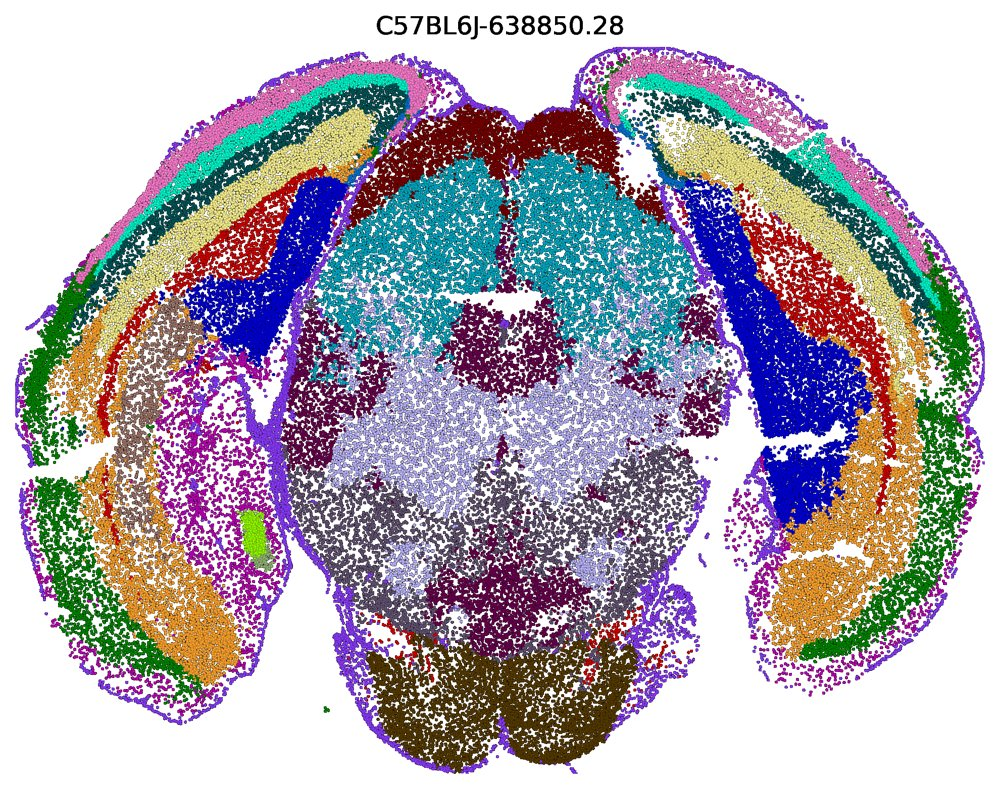

custom, k = 50: showing 1 of 5 sections (all in /home/rotation/sara_rotation/celltrans2-test/notebooks/notebook2/domains/custom_cluster_plots_k50)


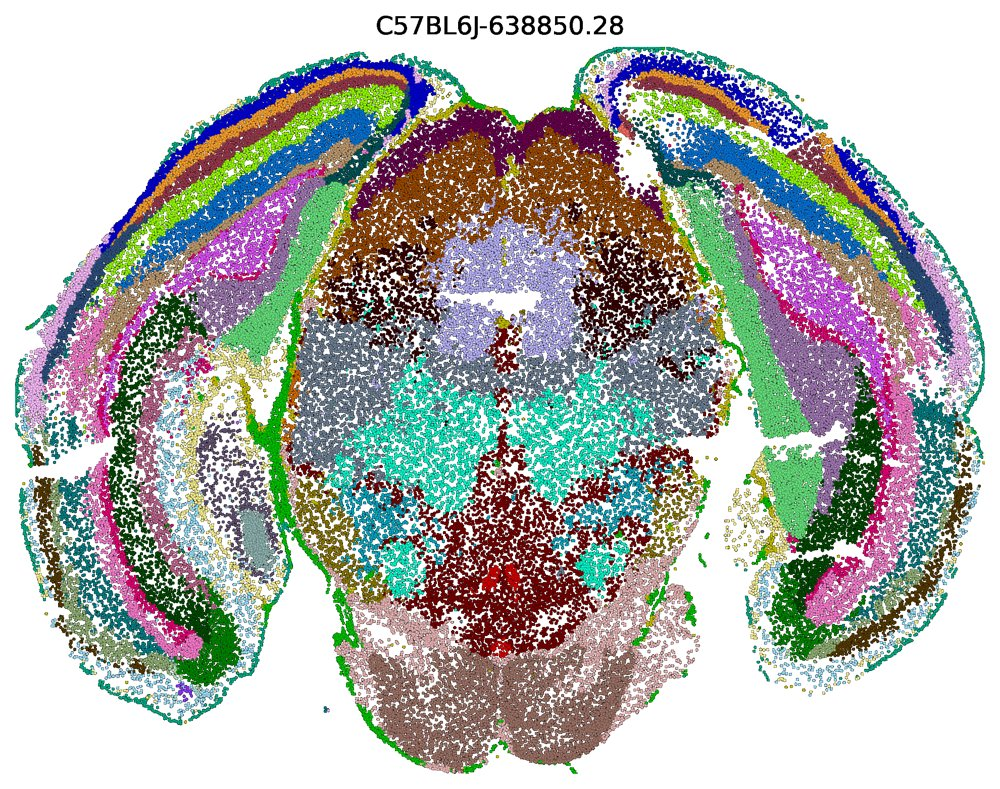

custom_smoothed, k = 20: showing 1 of 5 sections (all in /home/rotation/sara_rotation/celltrans2-test/notebooks/notebook2/domains/custom_smoothed_cluster_plots_k20)


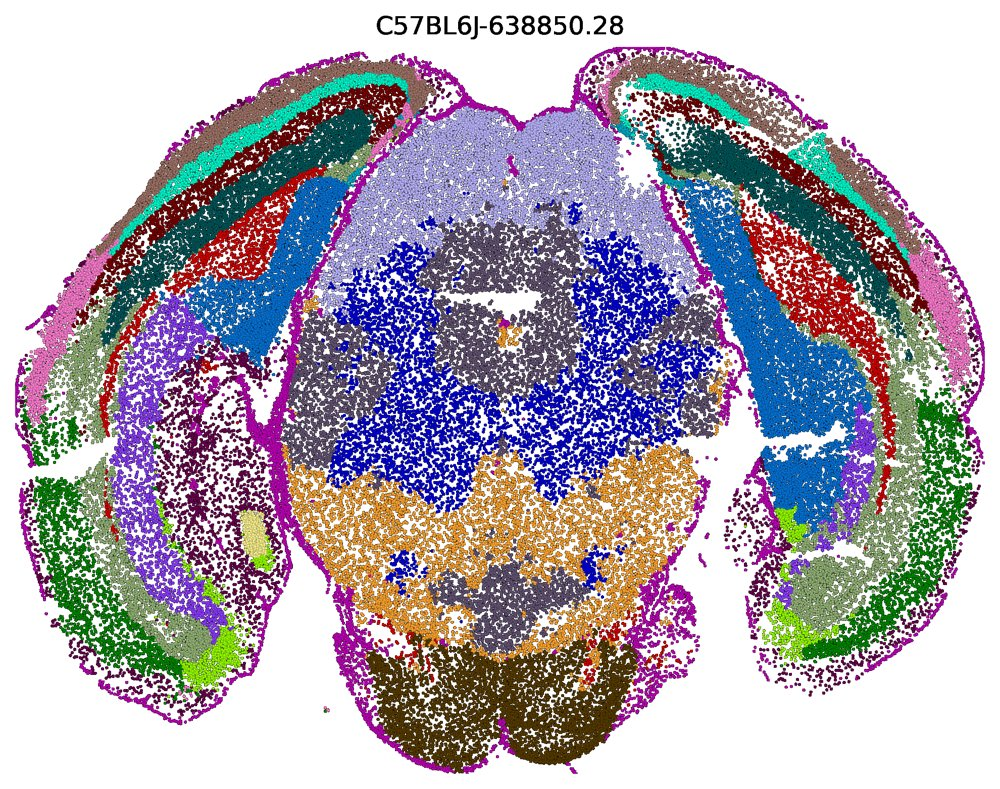

custom_smoothed, k = 50: showing 1 of 5 sections (all in /home/rotation/sara_rotation/celltrans2-test/notebooks/notebook2/domains/custom_smoothed_cluster_plots_k50)


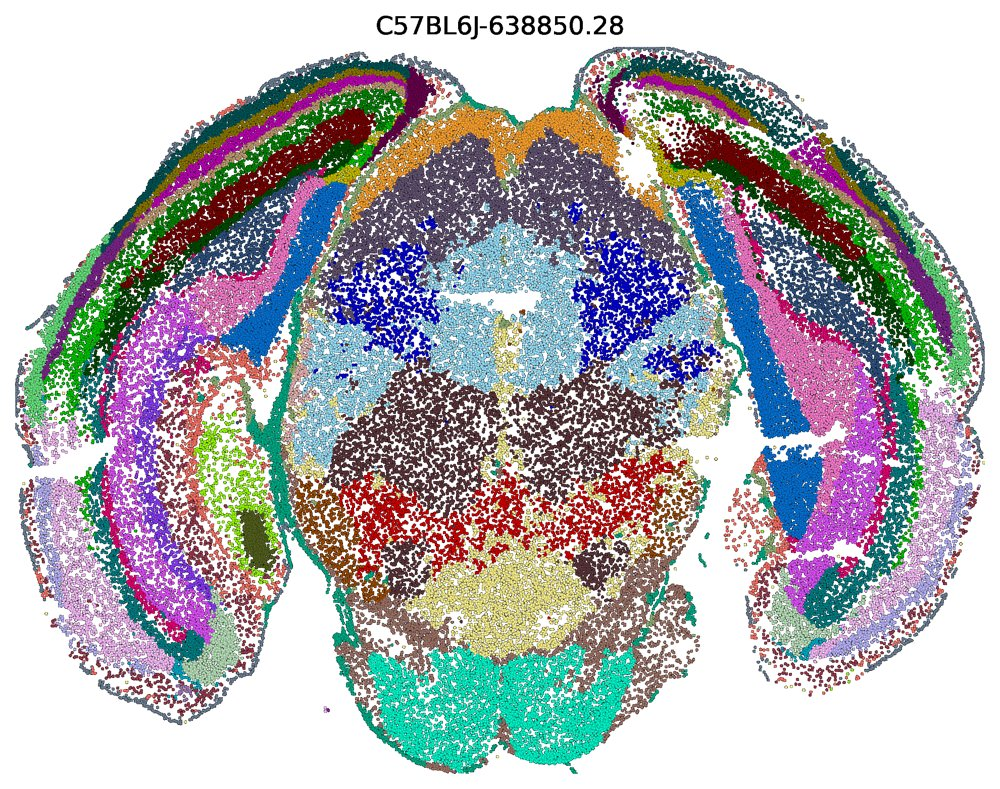

In [31]:
helper.show_domain_plots(DOMAINS_DIR, EMBEDDING_SETS, KS, n_show=1)

## Step 13: generate the HTML report (optional)
● TIMING depends on the number of cells, sections and clustering resolutions

Run this after Steps 9–11 have finished. It reads the saved assignments and writes a new,
self-contained `review.html` and `results.zip` under `WORK_DIR/html_reports/`. It does not retrain,
extract, smooth or cluster again. Training curves are recovered from the selected checkpoint's local
W&B history; missing values are reported rather than replaced with batch losses.

The report contains training diagnostics and maps for every section and k. If reference annotations
are supplied, it also shows reference–domain correspondence heatmaps: Pearson correlations between
cell-type proportions, with a fixed −1 to +1 color scale. Reference regions and discovered domains
need not have the same number of labels. The report has no separate composition-matrix panels.

`ct2_report.py` and `notebook_report.py` must be next to this notebook. Both are supplied in the
repository and use the existing environment. No separate launcher or execution manifest is required.
Section names come from the data. Set the report title, coordinate units and optional reference
columns below. To omit reference comparison, set `REFERENCE_COLUMNS = {}`. Reference rows are joined
by exact cell ID; a missing annotation excludes that cell from correspondence calculations, not from
training or the saved domain assignments. Colors are consistent across sections within each method
and k, but do not imply matched identities across methods or the reference.


In [ ]:
from notebook_report import report_from_notebook, read_reference_table, read_training_history, show_report

# REPLACE WITH YOUR DATA: display title, coordinate units and optional reference columns.
REPORT_NAME = WORK_DIR.name
REPORT_COORD_UNITS = "µm"
REFERENCE_FILE = RAW_METADATA
REFERENCE_ID_COLUMN = CELL_ID_COL
# The example uses CCF substructures. For other data, replace this mapping with
# {"Reference name": "your_annotation_column"}, or {} if there is no reference.
REFERENCE_COLUMNS = {"Reference regions": "parcellation_substructure"}
REFERENCE_FOR_K = None  # a single reference is compared at every k in KS
REFERENCE_DISPLAY_NAMES = {"Reference regions": "Reference"}

# Optional annotation-based enlargement; leave None for whole-section maps only.
# See HTML_REPORT.md for explicit crop bounds and other reference layouts.
REPORT_CROP = None
REPORT_CROP_NAME = "Enlargement"
REPORT_BOUNDARY_GRID = None
REPORT_BOUNDARY_DISTANCE = None


In [ ]:
# Read the completed checkpoint's local epoch averages; no W&B login is needed.
report_training = read_training_history(CHECKPOINT, expected_epochs=EPOCHS)
report_reference = read_reference_table(REFERENCE_FILE, REFERENCE_ID_COLUMN, REFERENCE_COLUMNS)

report_notes = report_training["notes"] + [
    f"{len(VALID_SECTIONS)} whole sections were withheld during training; clustering used all sections jointly.",
    "Reference correspondence is an exploratory comparison of cell-type composition, not an independent held-out clustering test.",
]
report_html = report_from_notebook(
    work_dir=WORK_DIR,
    embedding_sets=EMBEDDING_SETS,
    domains_dir=DOMAINS_DIR,
    ks=KS,
    dataset_name=REPORT_NAME,
    coordinate_units=REPORT_COORD_UNITS,
    n_genes=N_GENES,
    method_names={tag: "CellTransformer2 (+smoothing)" if Path(folder).resolve() == SMOOTHED_DIR.resolve()
                  else "CellTransformer2 (−smoothing)" for tag, folder in EMBEDDING_SETS.items()},
    reference_metadata=report_reference,
    reference_id_column=REFERENCE_ID_COLUMN,
    reference_columns=REFERENCE_COLUMNS,
    reference_for_k=REFERENCE_FOR_K if report_reference is not None else None,
    reference_display_names=REFERENCE_DISPLAY_NAMES,
    training_history=report_training["history"],
    notes=report_notes,
    provenance={"training": report_training["provenance"], "validation_sections": list(VALID_SECTIONS),
                "patch_size": PATCH_SIZE, "smoothing_sigma": SIGMA, "smoothing_neighbors": N_NEIGHBORS},
    crop_selection=REPORT_CROP if report_reference is not None else None,
    crop_name=REPORT_CROP_NAME,
    boundary_grid_size=REPORT_BOUNDARY_GRID,
    boundary_max_distance=REPORT_BOUNDARY_DISTANCE,
)
show_report(report_html)


## Known limitations
- **GPU selection for smoothing and clustering.** `celltransformer-smooth` and `celltransformer-cluster` have no
  device option, so Steps 10–11 set `CUDA_VISIBLE_DEVICES` to the first GPU in `DEVICES`.
- **Author-specific package defaults.** The config YAMLs point at `/data1/alexlee` and `/data2/alexlee`, and
  `celltransformer-cluster` defaults to `--output-base /data2/alexlee/embeddings`. This notebook overrides every
  one it uses; set them yourself if you run the commands directly. `config/data/zhuang.yaml` is missing
  `partition_strategy`.
- **cuML kNN distances are imprecise at large coordinates** (up to ~4 µm at ~10,000 µm, from float32 rounding).
  Neighbor sets were identical on the example sections and smoothed embeddings differed by <1% per cell.
- **Timings.** Some ● TIMING values are estimates.